In [43]:
import heapq
import math

import matplotlib.pyplot as plt
import networkx as nx

from IPython.display import JSON

In [64]:
## define the Peru weighted graph (km)
graph = {
    'A': {'B': 5, 'C': 4},
    'B': {'A': 5, 'F': 3, 'G': 9},
    'C': {'A': 4, 'F': 5},
    'F': {'B': 3, 'C': 5, 'G': 5},
    'G': {'B': 9, 'F': 5, 'H': 4},
    'H': {'G': 4}
}

graph

{'A': {'B': 5, 'C': 4},
 'B': {'A': 5, 'F': 3, 'G': 9},
 'C': {'A': 4, 'F': 5},
 'F': {'B': 3, 'C': 5, 'G': 5},
 'G': {'B': 9, 'F': 5, 'H': 4},
 'H': {'G': 4}}

In [65]:
## create the graph object
G = nx.Graph()

## load edges and weights
for source, neighbors in graph.items():
    for target, weight in neighbors.items():
        G.add_edge(source, target, weight=weight)

## show graph
print(G)

Graph with 6 nodes and 7 edges


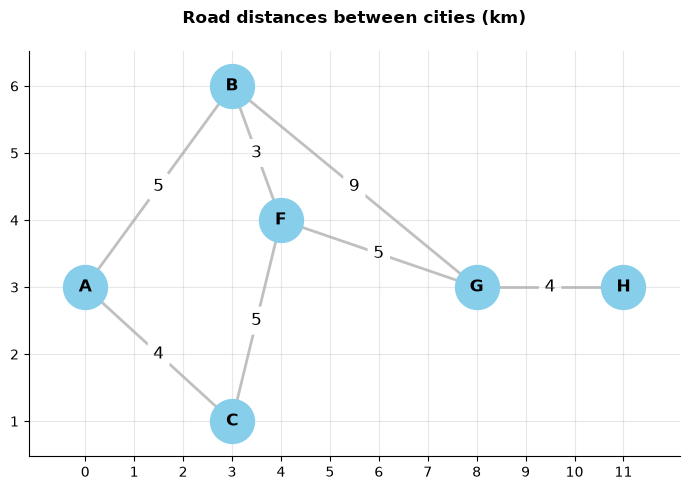

In [66]:
## set coordinates 
POSITIONS = {
    'A': (0, 3),
    'B': (3, 6),
    'C': (3, 1),
    'F': (4, 4),
    'G': (8, 3),
    'H': (11, 3)
}

## create plot
plt.figure(figsize=(7, 5))

## draw nodes, labels, and edges
nx.draw_networkx_nodes(G, POSITIONS, node_size=1000, node_shape='o', node_color='skyblue')
nx.draw_networkx_labels(G, POSITIONS, font_size=12, font_weight='bold', )
nx.draw_networkx_edges(G, POSITIONS, width=2, edge_color='silver')

## draw edge weights
weights = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(G, POSITIONS, edge_labels=weights, rotate=False, font_size=12)

## get current axes
ax = plt.gca()

## add ticks
ax.grid(True, alpha=0.3)

## show ticks and numeric labels
ax.set_xticks(range(0, 12))

ax.tick_params(
    bottom=True,
    left=True,
    labelbottom=True,
    labelleft=True
)

## hide the top and right borders
ax.spines[['top', 'right']].set_visible(False)

## plot graph
plt.title('Road distances between cities (km)', weight='bold', pad=20)
plt.tight_layout()
plt.show()

# Dijkstra

Only considers the actual accumulated cost from the start to node $n$.

$$f(n) = g(n)$$

where:

- $f(n)$: evaluation function; the frontier node with the lowest $f(n)$ is expanded first.
- $g(n)$: actual cost of the path from the start node to $n$.

# Greedy Best-First Search

Only considers the heuristic estimate of the cost from node $n$ to the goal; that is why it is "greedy".

$$f(n) = h(n)$$

where:

- $f(n)$: evaluation function; the frontier node with the lowest $f(n)$ is expanded first.
- $h(n)$: heuristic estimate of the cost from $n$ to the goal.

# A*

Combines both: the actual accumulated cost and the remaining heuristic estimate.

$$f(n) = g(n) + h(n)$$

where:

- $g(n)$: actual cost of the path from the start node to $n$.
- $h(n)$: heuristic estimate of the cost from $n$ to the goal.
- $f(n)$: estimated total cost of a path through $n$.

A* selects the frontier node with the lowest value of $f(n)$ for expansion.

### Euclidean Distance Heuristic

When nodes are positioned in a 2D plane, $h(n)$ can be defined using the straight-line distance (Euclidean distance) between node $n = (x_1, y_1)$ and goal node $g = (x_2, y_2)$:

$$h(n) = \sqrt{(x_2 - x_1)^2 + (y_2 - y_1)^2}$$

In [67]:
## heuristic: straight-line (euclidean) distance from n to the goal
def heuristic(source, goal):
    x1, y1 = source
    x2, y2 = goal
    distance = math.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2)
    
    return round(distance)

In [68]:
goal = 'G'

## get the heuristic distance from each node to the goal
for node, coord in POSITIONS.items():
    distance = heuristic(POSITIONS[node], POSITIONS[goal])

    print(f'{node} -> {goal}: {distance}')

A -> G: 8
B -> G: 6
C -> G: 5
F -> G: 4
G -> G: 0
H -> G: 3


In [78]:
start, goal = 'A', 'H'

## initialize the frontier
frontier = []

## initialize the cost dictionary
g = {node: float('inf') for node in graph}
g[start] = 0

## calculate f(n) = g(n) + h(n) for the start node
g_start = g[start]
h_start = heuristic(POSITIONS[start], POSITIONS[goal])
f_start = g_start + h_start

print(f'{start} -> {goal} | g = {g_start}, h = {h_start}, f = {f_start}')
print('=' * 80)

## add the start node to the frontier
heapq.heappush(frontier, (f_start, start))

## initialize the set of expanded nodes
visited = set()
visit_order = []

## initialize the parent dictionary
parents = {}

## initialize the step counter
step = 0

while frontier:
    step += 1
    print(f'Step {step}: Review the frontier {frontier}')

    ## extract the node with the lowest f(n)
    current_f, current_node = heapq.heappop(frontier)

    ## skip nodes that have already been expanded
    if current_node in visited:
        print(f'{" " * 4} Skip {current_node}: already visited')
        print('-' * 80)
        
        continue  

    ## check if the goal has been reached
    if current_node == goal:
        visit_order.append(current_node)
        print(f'{" " * 4} Goal reached!')
        break
    
    print(f'{" " * 4} Candidate {current_node} for expansion: f({current_node}) = {current_f}')

    ## mark the current node as expanded
    visited.add(current_node)
    visit_order.append(current_node)
    
    ## explore the neighbors of the current node
    for neighbor, cost in graph[current_node].items():

        ## skip neighbors that have already been expanded
        if neighbor in visited:
            print(f'{" " * 8} {neighbor}: already visited, skip')
            continue

        ## calculate the tentative cumulative cost
        g_n = g[current_node] + cost

        ## update the neighbor if a better path is found
        if g_n < g[neighbor]:

            ## update the cumulative cost and parent
            previous_g = g[neighbor]
            g[neighbor] = g_n
            parents[neighbor] = current_node

            ## calculate f(n) = g(n) + h(n) for the neighbor
            h_n = heuristic(POSITIONS[neighbor], POSITIONS[goal])
            f_n = g_n + h_n

            ## add the neighbor to the frontier
            heapq.heappush(frontier, (f_n, neighbor))

            print(f'{" " * 8} Add {neighbor}: update g = {previous_g} -> {g_n}, h = {h_n}, f = {f_n}')
        
        else:
            print(f'{" " * 8} {neighbor}: no improvement (new g = {g_n:.2f}, best g = {g[neighbor]:.2f})')

    ## display the current search state
    print(f'{" " * 4} Visited  : {visit_order}')
    print(f'{" " * 4} Parents  : {parents}')
    print('-' * 80)

A -> H | g = 0, h = 11, f = 11
Step 1: Review the frontier [(11, 'A')]
     Candidate A for expansion: f(A) = 11
         Add B: update g = inf -> 5, h = 9, f = 14
         Add C: update g = inf -> 4, h = 8, f = 12
     Visited  : ['A']
     Parents  : {'B': 'A', 'C': 'A'}
--------------------------------------------------------------------------------
Step 2: Review the frontier [(12, 'C'), (14, 'B')]
     Candidate C for expansion: f(C) = 12
         A: already visited, skip
         Add F: update g = inf -> 9, h = 7, f = 16
     Visited  : ['A', 'C']
     Parents  : {'B': 'A', 'C': 'A', 'F': 'C'}
--------------------------------------------------------------------------------
Step 3: Review the frontier [(14, 'B'), (16, 'F')]
     Candidate B for expansion: f(B) = 14
         A: already visited, skip
         Add F: update g = 9 -> 8, h = 7, f = 15
         Add G: update g = inf -> 14, h = 3, f = 17
     Visited  : ['A', 'C', 'B']
     Parents  : {'B': 'A', 'C': 'A', 'F': 'B', 'G': 

In [76]:
visit_order

['A', 'C', 'B', 'F', 'G', 'H']

In [77]:
path = [goal]
while path[-1] != start:
    path.append(parents[path[-1]])

path

['H', 'G', 'F', 'B', 'A']

In [72]:
path[-1]

'A'

In [73]:
parents

{'B': 'A', 'C': 'A', 'F': 'B', 'G': 'F', 'H': 'G'}

In [74]:
path[-1]

'A'